In [ ]:
# =====================================================================
# Part II - Image Colorization - TEMPLATE
# =====================================================================
#
# Task: take a grayscale image and predict its colors.
#
# You build and train the model any way you want (autoencoder, VAE, GAN, ...).
#
# The grader will:
#   1. run your model class + load_model() to load your saved weights,
#   2. call colorize() on their own images,
#   3. compare your output to hidden color images (PSNR / MSE).
#
# So you MUST keep the 3 fixed rules below.
# =====================================================================
#
# ---------------------------------------------------------------------
# FIXED RULES (do not change)
# ---------------------------------------------------------------------
#
# 1. Save your trained weights as a state_dict:
#        torch.save(model.state_dict(), "weights.pth")
#    Submit this "weights.pth" file together with your notebook.
#
# 2. All images are 256 x 256 PNG.
#    colorize() input  : grayscale array, shape (256, 256), float in [0, 1]
#    colorize() output : RGB array,       shape (256, 256, 3), float in [0, 1]
#
# 3. Do file loading OUTSIDE colorize() (see the demo at the bottom).
#    colorize() only takes arrays, not file paths.
# ---------------------------------------------------------------------

In [1]:
import numpy as np
import torch
import torch.nn as nn

IMG_SIZE = 256

 Model Architecture

A small U-Net architecture is used to map a 1-channel grayscale image to a 3-channel RGB image.

In [2]:
# ---------------------------------------------------------------------
# 1) YOUR MODEL
# ---------------------------------------------------------------------
# Define your architecture here.  This is only the layers,
# no training happens when this class is created.

class ConvBlock(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, 3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, 3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
        )

    def forward(self, x):
        return self.block(x)


class ColorizeModel(nn.Module):
    def __init__(self):
        super().__init__()

        # Encoder
        self.enc1 = ConvBlock(1, 32)
        self.enc2 = ConvBlock(32, 64)
        self.enc3 = ConvBlock(64, 128)
        self.enc4 = ConvBlock(128, 256)

        self.pool = nn.MaxPool2d(2)

        # Bottleneck
        self.bottleneck = ConvBlock(256, 512)

        # Decoder
        self.up4 = nn.ConvTranspose2d(512, 256, 2, stride=2)
        self.dec4 = ConvBlock(512, 256)

        self.up3 = nn.ConvTranspose2d(256, 128, 2, stride=2)
        self.dec3 = ConvBlock(256, 128)

        self.up2 = nn.ConvTranspose2d(128, 64, 2, stride=2)
        self.dec2 = ConvBlock(128, 64)

        self.up1 = nn.ConvTranspose2d(64, 32, 2, stride=2)
        self.dec1 = ConvBlock(64, 32)

        self.output = nn.Sequential(
            nn.Conv2d(32, 3, kernel_size=1),
            nn.Sigmoid()
        )

    def forward(self, x):
        # Encoder
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))
        e4 = self.enc4(self.pool(e3))

        # Bottleneck
        b = self.bottleneck(self.pool(e4))

        # Decoder + skip connections
        d4 = self.up4(b)
        d4 = self.dec4(torch.cat([d4, e4], dim=1))

        d3 = self.up3(d4)
        d3 = self.dec3(torch.cat([d3, e3], dim=1))

        d2 = self.up2(d3)
        d2 = self.dec2(torch.cat([d2, e2], dim=1))

        d1 = self.up1(d2)
        d1 = self.dec1(torch.cat([d1, e1], dim=1))

        return self.output(d1)


In [3]:
model = ColorizeModel()

x = torch.randn(1, 1, IMG_SIZE, IMG_SIZE)
y = model(x)

print("Input shape:", x.shape)
print("Output shape:", y.shape)
print("Output range:", y.min().item(), "to", y.max().item())

Input shape: torch.Size([1, 1, 256, 256])
Output shape: torch.Size([1, 3, 256, 256])
Output range: 0.0713113322854042 to 0.8058897256851196


 Data Preparation

We use the Caltech101 dataset, resize all images to 256×256, convert them to RGB, and split the data into training and validation sets.

In [4]:
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, random_split

# Every image will be RGB and 256x256
image_transform = transforms.Compose([
    transforms.Lambda(lambda img: img.convert("RGB")),
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
])

# Download Caltech101
full_dataset = datasets.Caltech101(
    root="./data",
    download=True,
    transform=image_transform
)

# Reproducible train/validation split
train_size = int(0.8 * len(full_dataset))
val_size = len(full_dataset) - train_size

generator = torch.Generator().manual_seed(42)

train_dataset, val_dataset = random_split(
    full_dataset,
    [train_size, val_size],
    generator=generator
)

BATCH_SIZE = 4

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

print("Total images:", len(full_dataset))
print("Training images:", len(train_dataset))
print("Validation images:", len(val_dataset))

100%|██████████| 137M/137M [00:01<00:00, 110MB/s]


Total images: 8677
Training images: 6941
Validation images: 1736


 Training Setup

The RGB images are converted to grayscale inputs, while the original RGB images are used as training targets.

In [5]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

def rgb_to_gray(rgb):
    # rgb shape: [batch, 3, 256, 256]
    r = rgb[:, 0:1]
    g = rgb[:, 1:2]
    b = rgb[:, 2:3]

    gray = 0.299 * r + 0.587 * g + 0.114 * b
    return gray

# Check one batch
rgb_images, _ = next(iter(train_loader))
gray_images = rgb_to_gray(rgb_images)

print("RGB batch shape:", rgb_images.shape)
print("Gray batch shape:", gray_images.shape)
print("RGB range:", rgb_images.min().item(), "to", rgb_images.max().item())
print("Gray range:", gray_images.min().item(), "to", gray_images.max().item())

Device: cuda
RGB batch shape: torch.Size([4, 3, 256, 256])
Gray batch shape: torch.Size([4, 1, 256, 256])
RGB range: 0.0 to 1.0
Gray range: 0.0 to 1.0


 Model Training

The model is trained to reconstruct the original RGB image from its grayscale version.  
L1 loss is used, and the model with the best validation loss is saved.

In [6]:
model = ColorizeModel().to(device)

criterion = nn.L1Loss()
optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=1e-3,
    weight_decay=1e-4
)

EPOCHS = 6
best_val_loss = float("inf")

# Mixed precision makes training faster and uses less GPU memory
scaler = torch.cuda.amp.GradScaler(enabled=(device.type == "cuda"))

for epoch in range(EPOCHS):

    # -------------------------
    # Training
    # -------------------------
    model.train()
    train_loss = 0.0

    for rgb_images, _ in train_loader:
        rgb_images = rgb_images.to(device)
        gray_images = rgb_to_gray(rgb_images)

        optimizer.zero_grad()

        with torch.cuda.amp.autocast(enabled=(device.type == "cuda")):
            outputs = model(gray_images)
            loss = criterion(outputs, rgb_images)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        train_loss += loss.item() * rgb_images.size(0)

    train_loss /= len(train_loader.dataset)

    # -------------------------
    # Validation
    # -------------------------
    model.eval()
    val_loss = 0.0

    with torch.no_grad():
        for rgb_images, _ in val_loader:
            rgb_images = rgb_images.to(device)
            gray_images = rgb_to_gray(rgb_images)

            with torch.cuda.amp.autocast(enabled=(device.type == "cuda")):
                outputs = model(gray_images)
                loss = criterion(outputs, rgb_images)

            val_loss += loss.item() * rgb_images.size(0)

    val_loss /= len(val_loader.dataset)

    print(
        f"Epoch {epoch + 1}/{EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Validation Loss: {val_loss:.4f}"
    )

    # Save the best model only
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        torch.save(model.state_dict(), "weights.pth")
        print("Best model saved ✅")

print("\nTraining finished.")
print("Best validation loss:", best_val_loss)

/tmp/ipykernel_1710/4268006064.py:14: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=(device.type == "cuda"))
/tmp/ipykernel_1710/4268006064.py:30: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=(device.type == "cuda")):
/tmp/ipykernel_1710/4268006064.py:53: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=(device.type == "cuda")):


Epoch 1/6 | Train Loss: 0.0793 | Validation Loss: 0.0566
Best model saved ✅
Epoch 2/6 | Train Loss: 0.0661 | Validation Loss: 0.0629
Epoch 3/6 | Train Loss: 0.0599 | Validation Loss: 0.0667
Epoch 4/6 | Train Loss: 0.0573 | Validation Loss: 0.0588
Epoch 5/6 | Train Loss: 0.0555 | Validation Loss: 0.0556
Best model saved ✅
Epoch 6/6 | Train Loss: 0.0540 | Validation Loss: 0.0564

Training finished.
Best validation loss: 0.055564865195256774


In [7]:
# ---------------------------------------------------------------------
# 2) LOAD YOUR TRAINED WEIGHTS
# ---------------------------------------------------------------------
# Rebuilds the empty model and loads the saved numbers.
# This is instant - no training.
def load_model(weights_path="weights.pth"):
    model = ColorizeModel()
    model.load_state_dict(torch.load(weights_path, map_location="cpu"))
    model.eval()
    return model

In [8]:
# ---------------------------------------------------------------------
# 3) COLORIZE ONE IMAGE
# ---------------------------------------------------------------------
# gray_img: numpy array, shape (256, 256), float in [0, 1]
# returns : numpy array, shape (256, 256, 3), float in [0, 1]
def colorize(gray_img, model):
    # to tensor: (1, 1, 256, 256)
    x = torch.from_numpy(gray_img).float().view(1, 1, IMG_SIZE, IMG_SIZE)

    with torch.no_grad():           # no gradients needed for inference
        y = model(x)                # (1, 3, 256, 256)

    # back to numpy image (256, 256, 3)
    out = y.squeeze(0).permute(1, 2, 0).cpu().numpy()
    return np.clip(out, 0.0, 1.0)

 Final Inference Test

We test the exact `load_model()` and `colorize()` functions that will be used by the grader.

In [9]:
# Load the saved model exactly as the grader will
test_model = load_model("weights.pth")

# Take one validation image
rgb_batch, _ = next(iter(val_loader))
rgb_img = rgb_batch[0]

# Convert it to grayscale
gray_img = rgb_to_gray(rgb_img.unsqueeze(0))[0, 0].numpy()

# Run the required colorize() function
predicted_img = colorize(gray_img, test_model)

print("Gray input shape:", gray_img.shape)
print("Predicted output shape:", predicted_img.shape)
print("Predicted range:", predicted_img.min(), "to", predicted_img.max())

Gray input shape: (256, 256)
Predicted output shape: (256, 256, 3)
Predicted range: 0.05549097 to 0.9708825


 Validation Results

We compare the grayscale input, the model prediction, and the original RGB image on validation samples that were not used for training.

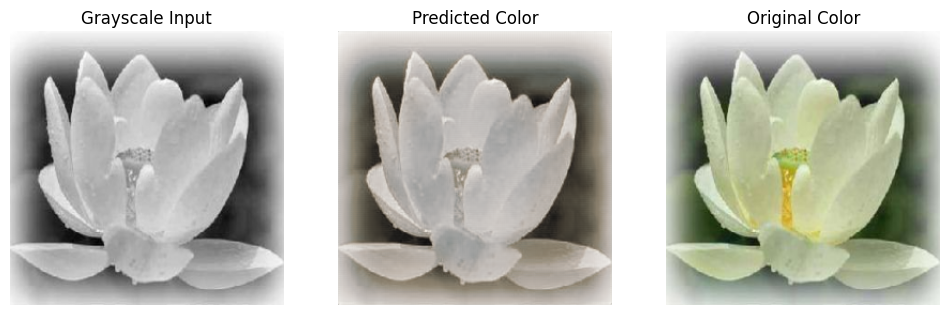

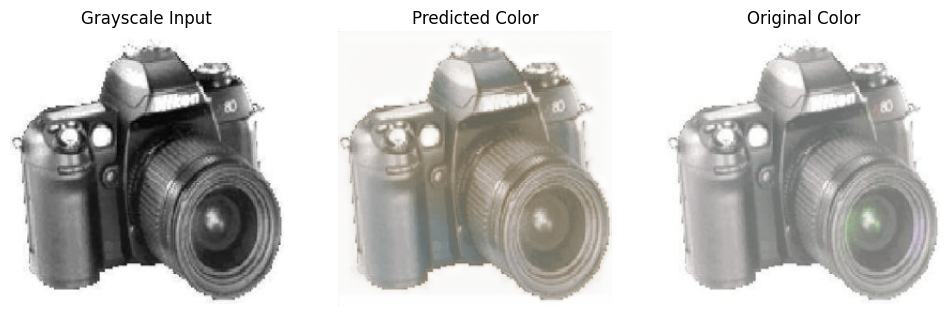

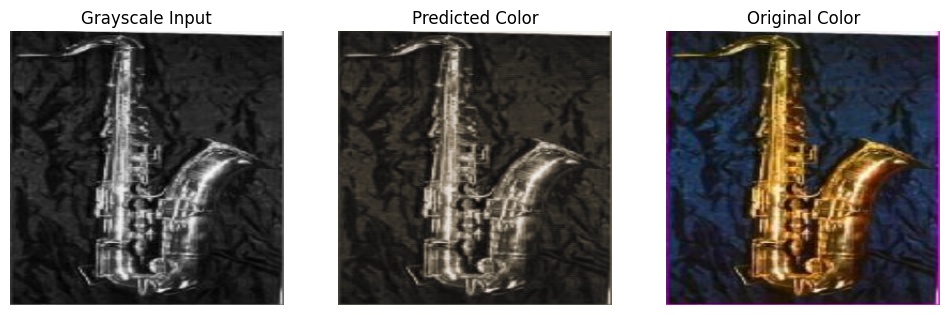

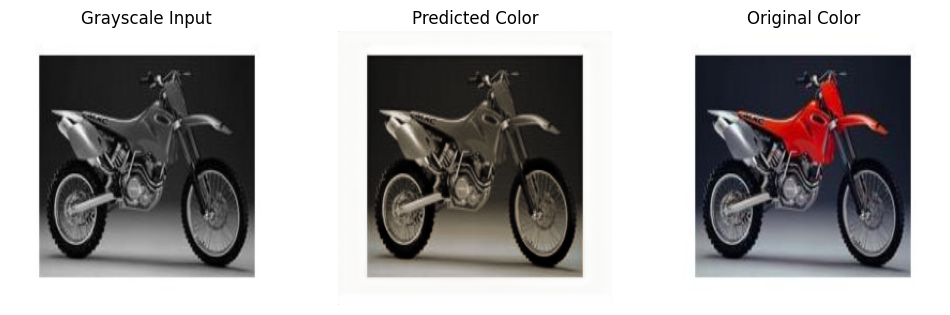

In [10]:
import matplotlib.pyplot as plt

# Load the best saved model
val_model = load_model("weights.pth")

# Get one validation batch
rgb_images, _ = next(iter(val_loader))

num_examples = min(4, len(rgb_images))

for i in range(num_examples):
    rgb_img = rgb_images[i]
    gray_img = rgb_to_gray(rgb_img.unsqueeze(0))[0, 0].numpy()

    predicted_img = colorize(gray_img, val_model)

    plt.figure(figsize=(12, 4))

    plt.subplot(1, 3, 1)
    plt.imshow(gray_img, cmap="gray")
    plt.title("Grayscale Input")
    plt.axis("off")

    plt.subplot(1, 3, 2)
    plt.imshow(predicted_img)
    plt.title("Predicted Color")
    plt.axis("off")

    plt.subplot(1, 3, 3)
    plt.imshow(rgb_img.permute(1, 2, 0).numpy())
    plt.title("Original Color")
    plt.axis("off")

    plt.show()

 Quantitative Evaluation

We evaluate the model on the full validation set using MSE and PSNR, matching the metrics used by the grader.

In [11]:
import math

eval_model = load_model("weights.pth")
eval_model = eval_model.to(device)
eval_model.eval()

total_mse = 0.0
total_images = 0

with torch.no_grad():
    for rgb_images, _ in val_loader:
        rgb_images = rgb_images.to(device)
        gray_images = rgb_to_gray(rgb_images)

        predictions = eval_model(gray_images)

        mse_per_image = ((predictions - rgb_images) ** 2).mean(dim=(1, 2, 3))

        total_mse += mse_per_image.sum().item()
        total_images += rgb_images.size(0)

mean_mse = total_mse / total_images
psnr = 10 * math.log10(1.0 / mean_mse)

print("Validation MSE:", mean_mse)
print("Validation PSNR:", psnr, "dB")

Validation MSE: 0.00764564847550033
Validation PSNR: 21.165856734448948 dB
